# Exercițiul 1: Controlul calității într-o fabrică (inferență Bayesiană)

Avem datele inițiale:
* Distribuția a priori: $\theta \sim Beta(\alpha=2, \beta=18)$.
* Eșantion: $n=50$ componente testate, dintre care $y=8$ sunt defecte.

### a) Modelul probabilistic
Deoarece testele sunt independente condiționat de $\theta$, numărul de componente defecte $Y$ urmează o distribuție binomială:
$$Y | \theta \sim Binomial(n, \theta)$$
Funcția de verosimilitate (likelihood) reprezintă probabilitatea de a observa exact $y$ defecte, având parametrul $\theta$:
$$P(Y=y | \theta) = \binom{n}{y} \theta^y (1-\theta)^{n-y}$$

### b) Actualizarea Bayesiană
Conform teoremei lui Bayes, distribuția a posteriori este proporțională cu produsul dintre verosimilitate și distribuția a priori:
$$p(\theta | y) \propto P(Y=y | \theta) \cdot p(\theta)$$
Ignorând constantele de normalizare, avem:
$$p(\theta | y) \propto \left[ \theta^y (1-\theta)^{n-y} \right] \cdot \left[ \theta^{\alpha-1} (1-\theta)^{\beta-1} \right]$$
$$p(\theta | y) \propto \theta^{y+\alpha-1} (1-\theta)^{n-y+\beta-1}$$
Aceasta este exact forma nucleului unei distribuții Beta. Datorită conjugării Beta-Binomial, posteriorul este o nouă distribuție Beta cu parametrii actualizați:
$$\theta | y \sim Beta(\alpha + y, \beta + n - y)$$
Înlocuind cu datele noastre ($\alpha=2, \beta=18, y=8, n=50$):
$$\theta | y \sim Beta(2 + 8, 18 + 50 - 8) \implies \theta | y \sim Beta(10, 60)$$

### c) Estimarea parametrului
1. **Estimatorul de Maximă Verosimilitate (MLE):** Se bazează strict pe datele observate.
   $$\hat{\theta}_{MLE} = \frac{y}{n} = \frac{8}{50} = 0.160$$
2. **Estimatorul MAP (Maximum A Posteriori):** Este modulul distribuției a posteriori $Beta(10, 60)$. Pentru $Beta(a, b)$, formula modului este $\frac{a-1}{a+b-2}$.
   $$\hat{\theta}_{MAP} = \frac{10-1}{10+60-2} = \frac{9}{68} \approx 0.132$$
3. **Media a posteriori:** Reprezintă valoarea așteptată (speranța matematică) a noii distribuții. Pentru $Beta(a, b)$, formula este $\frac{a}{a+b}$.
   $$E[\theta | y] = \frac{10}{10+60} = \frac{10}{70} \approx 0.143$$
*Explicația diferențelor:* MLE ignoră informația a priori și depinde doar de eșantion ($16\%$). Deoarece priorul era foarte sceptic (cu o medie de $2/20 = 10\%$), acesta "trage" estimările posterioare (Media și MAP) în jos, spre stânga, reflectând un echilibru între credința inițială și datele noi.

### g) Predicție Bayesiană (Formulă)
Fie $X$ numărul de componente defecte dintr-un nou eșantion de 10 componente. Vrem probabilitatea $P(X=0 | Y=8)$. Aceasta se obține integrând probabilitatea condiționată peste toată incertitudinea lui $\theta$ (folosind posteriorul):
$$P(X=0 | Y=8) = \int_{0}^{1} (1-\theta)^{10} \cdot p(\theta | Y=8) d\theta$$
Știm că $p(\theta | Y=8) = \frac{1}{B(10, 60)} \theta^{9} (1-\theta)^{59}$. Înlocuind în integrală, obținem:
$$P(X=0 | Y=8) = \frac{1}{B(10, 60)} \int_{0}^{1} \theta^{9} (1-\theta)^{69} d\theta = \frac{B(10, 70)}{B(10, 60)}$$
(Această valoare va fi calculată exact în codul Python).

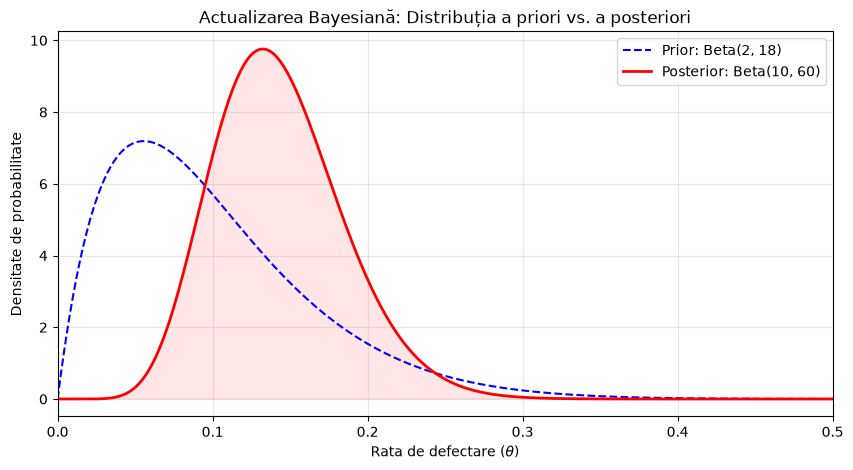

Explicație (pct d):
Datele observate (8 defecte din 50, adica 16%) au 'mutat' distribuția 
spre dreapta fata de priorul initial (care avea o medie de 10%). 
De asemenea, posteriorul este mult mai ascutit, ceea ce arata ca 
incertitudinea noastra a scazut dupa ce am testat 50 de piese.

e) Intervalul credibil 95% pentru rata de defectare este: [0.0717, 0.2332]
Interpretare: Suntem 95% siguri (condiționat de model și de datele observate)
că rata reală de defectare se află undeva între 7.17 % și 23.32 %.

f) Probabilitatea a posteriori ca theta < 0.10 este: 0.1484 (aprox 14.8%)
Decizie: Fabrica își dorește o rată de defectare sub 10%, însă datele
oferă doar o certitudine de ~15% că acest lucru se întâmplă. Deci,
cerința NU este puternic susținută de date (fabrica are o problemă).

g) Probabilitatea predictivă ca 0 piese din următoarele 10 să fie defecte: 0.2360
Interpretare: Desi rata medie de defectare estimata e in jur de 14%,
daca tragem inca 10 piese noi, exista sanse de aprox. 22.5% 

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import beta
import scipy.special as sp

# Parametrii distributiilor
a_prior, b_prior = 2, 18
y, n = 8, 50
a_post, b_post = a_prior + y, b_prior + n - y  # 10, 60

# d) Vizualizare
theta_vals = np.linspace(0, 1, 1000)
pdf_prior = beta.pdf(theta_vals, a_prior, b_prior)
pdf_post = beta.pdf(theta_vals, a_post, b_post)

plt.figure(figsize=(10, 5))
plt.plot(theta_vals, pdf_prior, label='Prior: Beta(2, 18)', color='blue', linestyle='--')
plt.plot(theta_vals, pdf_post, label='Posterior: Beta(10, 60)', color='red', linewidth=2)
plt.fill_between(theta_vals, pdf_post, color='red', alpha=0.1)
plt.title('Actualizarea Bayesiană: Distribuția a priori vs. a posteriori')
plt.xlabel(r'Rata de defectare ($\theta$)')
plt.ylabel('Densitate de probabilitate')
plt.xlim(0, 0.5)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

print("Explicație (pct d):")
print("Datele observate (8 defecte din 50, adica 16%) au 'mutat' distribuția ")
print("spre dreapta fata de priorul initial (care avea o medie de 10%). ")
print("De asemenea, posteriorul este mult mai ascutit, ceea ce arata ca ")
print("incertitudinea noastra a scazut dupa ce am testat 50 de piese.\n")

# e) Incertitudine: Interval credibil central de 95%
ic_jos, ic_sus = beta.ppf([0.025, 0.975], a_post, b_post)
print(f"e) Intervalul credibil 95% pentru rata de defectare este: [{ic_jos:.4f}, {ic_sus:.4f}]")
print("Interpretare: Suntem 95% siguri (condiționat de model și de datele observate)")
print("că rata reală de defectare se află undeva între", round(ic_jos*100, 2), "% și", round(ic_sus*100, 2), "%.\n")

# f) Decizie practica: Probabilitatea ca theta < 0.10
prob_sub_10 = beta.cdf(0.10, a_post, b_post)
print(f"f) Probabilitatea a posteriori ca theta < 0.10 este: {prob_sub_10:.4f} (aprox {prob_sub_10*100:.1f}%)")
print("Decizie: Fabrica își dorește o rată de defectare sub 10%, însă datele")
print("oferă doar o certitudine de ~15% că acest lucru se întâmplă. Deci,")
print("cerința NU este puternic susținută de date (fabrica are o problemă).\n")

# g) Predictie Bayesiana: P(X=0 | Y=8) in 10 piese noi
# Calculam folosind formula B(10, 70) / B(10, 60) demonstrata mai sus
prob_0_defecte = sp.beta(a_post, b_post + 10) / sp.beta(a_post, b_post)
print(f"g) Probabilitatea predictivă ca 0 piese din următoarele 10 să fie defecte: {prob_0_defecte:.4f}")
print("Interpretare: Desi rata medie de defectare estimata e in jur de 14%,")
print("daca tragem inca 10 piese noi, exista sanse de aprox. 22.5% ca NICIUNA")
print("sa nu fie defecta (tinand cont de toata incertitudinea modelului).")